# Tugas Kelompok Berbasis Kasus 01

### Anggota Kelompok

1. Andika Dinata (123140096)
2. Ardiansyah Fernando (123140102)

Kami memilih dataset Medical Insurance Cost dan Iris Flower.

Untuk masalah regresi kami memilih dataset Medical Insurance Cost berisi data demografis dan indikator kesehatan seseorang (BMI, usia, status merokok) untuk memprediksi variabel kontinu insurance charges. Algoritmanya kami menggunakan Linear Regression yang dapat memetakan variabel-variabel independen menuju y (variabel target).

Untuk masalah klasifikasi kami menggunakan dataset Iris Flower berisi data multivariat morfologi (sepal length dan width, dan petal length dan width) 3 kelas bunga yaitu iris setosa, iris virginica, dan iris versicolor. Algoritmanya kami menggunakan Support Vector Machine (SVM) karena keunggulannya dalam menemukan hyperplane dengan margin terbesar dalam ruang data yang berdimensi rendah.

In [ ]:
!pip install -q kagglehub pandas numpy scikit-learn matplotlib

In [ ]:
from pathlib import Path

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    precision_score,
    r2_score,
    recall_score,
)
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler

Melakukan import package python yang dibutuhkan untuk mendownload dataset, melakukan inspeksi, membuat model menggunakan scikit-learn, dan melakukan evaluasi menggunakan matplotlib secara visual.

In [ ]:
RANDOM_STATE = 42
TEST_SIZE = 0.2
CROSS_VALIDATION_FOLDS = 5
INSURANCE_DATASET_HANDLE = "mosapabdelghany/medical-insurance-cost-dataset"
IRIS_DATASET_HANDLE = "arshid/iris-flower-dataset"

Kami melakukan split data menggunakan perbandingkan 80% dataset untuk training dan 20% untuk testing.

Untuk cross validationnya kami memilih 5 folds, berdasarkan literatur yang telah dibaca (https://hastie.su.domains/ElemStatLearn/), kami memutuskan menggunakan fold 5 karena variansi rendah dan komputasi yang efisien dengan kompromi terbaik.

# Medical Insurance Cost (Linear Regression)

## Load Data

In [ ]:
insurance_dataset_directory = Path(kagglehub.dataset_download(INSURANCE_DATASET_HANDLE))
insurance_csv_paths = sorted(insurance_dataset_directory.rglob("*.csv"))
insurance_dataframe = pd.read_csv(insurance_csv_paths[0])
insurance_dataframe.columns = insurance_dataframe.columns.str.strip().str.lower()

Using Colab cache for faster access to the 'medical-insurance-cost-dataset' dataset.


Download dataset menggunakan kagglehub kemudian disimpan dalam dataframe

## Data Inspection

In [ ]:
display(insurance_dataframe.head())
insurance_dataframe.info()
display(insurance_dataframe.describe(include="all").T)
print("Missing values per column:")
print(insurance_dataframe.isna().sum())
print("Duplicated rows:", insurance_dataframe.duplicated().sum())

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,1338.0,NaN,NaN,NaN,39.207025,14.04996,18.0,27.0,39.0,51.0,64.0
sex,1338,2,male,676,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bmi,1338.0,NaN,NaN,NaN,30.663397,6.098187,15.96,26.29625,30.4,34.69375,53.13
children,1338.0,NaN,NaN,NaN,1.094918,1.205493,0.0,0.0,1.0,2.0,5.0
smoker,1338,2,no,1064,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,1338,4,southeast,364,NaN,NaN,NaN,NaN,NaN,NaN,NaN
charges,1338.0,NaN,NaN,NaN,13270.422265,12110.011237,1121.8739,4740.28715,9382.033,16639.912515,63770.42801


Missing values per column:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64
Duplicated rows: 1


Hasil pengecekkan menunjukkan tidak ada data yang hilang (missing values) dan terdapat 1 baris data duplikat yang menunjukkan kualitas dataset baik dan siap diproses.

## Preprocessing

In [ ]:
insurance_dataframe = insurance_dataframe.drop_duplicates().reset_index(drop=True)

insurance_target_column = "charges"
insurance_features = insurance_dataframe.drop(columns=[insurance_target_column])
insurance_target = insurance_dataframe[insurance_target_column]

insurance_numeric_columns = insurance_features.select_dtypes(include="number").columns.tolist()
insurance_categorical_columns = insurance_features.select_dtypes(exclude="number").columns.tolist()

(
    insurance_train_raw_features,
    insurance_test_raw_features,
    insurance_train_target,
    insurance_test_target,
) = train_test_split(
    insurance_features,
    insurance_target,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
)

insurance_numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
insurance_categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(drop="first", sparse_output=False)),
])
insurance_preprocessor = ColumnTransformer(
    [
        ("numeric", insurance_numeric_pipeline, insurance_numeric_columns),
        ("categorical", insurance_categorical_pipeline, insurance_categorical_columns),
    ],
    verbose_feature_names_out=False,
)
insurance_preprocessor.set_output(transform="pandas")

insurance_train_features = insurance_preprocessor.fit_transform(insurance_train_raw_features)
insurance_test_features = insurance_preprocessor.transform(insurance_test_raw_features)

display(insurance_train_features.head())
print("Train shape:", insurance_train_features.shape)
print("Test shape:", insurance_test_features.shape)

,age,bmi,children,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
1113,-1.157680,-0.996928,-0.907908,1.0,0.0,0.0,0.0,0.0
967,-1.300619,-0.792762,0.766904,1.0,0.0,0.0,0.0,0.0
598,0.914926,1.154664,0.766904,0.0,0.0,1.0,0.0,0.0
170,1.701087,1.806837,-0.907908,1.0,0.0,0.0,1.0,0.0
275,0.557580,-0.651417,0.766904,0.0,0.0,0.0,0.0,0.0


Train shape: (1069, 8)
Test shape: (268, 8)


Baris yang duplikat dihapus,

kolom targetnya adalah charges, dan kolom inputnya adalah sisa kolom-kolom selain charges. Data kemudian displit terlebih dahulu sebelum dilakukan pemrosesan.

Kolom yang tipe datanya numerik distandarisasi menggunakan StandardScaler, sedangkan kolom yang tipe datanya kategorikal diencode menggunakan OneHotEncoder. Untuk kolom yang datanya hilang, digunakan SimpleImputer yang mengisi nilai hilang (jika numerik mengambil nilai median, jika kategorikal diambil modusnya)

Untuk hasil akhirnya ada 3 kolom numerik (age, bmi, children) dan 5 kolom kategori yang nilainya biner (sex_male, smoker_yes, region_northwest, region_southeast, region_southwest) sehingga totalnya ada 8 kolom fitur.

## Model Training

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score


class LinearRegressionModel:
    def __init__(self):
        self.estimator = LinearRegression()

    def train(self, features, target):
        self.estimator.fit(features, target)
        return self

    def predict(self, features):
        return self.estimator.predict(features)

    def cross_validate(self, features, target, folds):
        return cross_val_score(self.estimator, features, target, cv=folds, scoring="r2")

    def get_coefficients(self, feature_names):
        coefficients = pd.Series(self.estimator.coef_, index=feature_names)
        return coefficients.sort_values(key=np.abs, ascending=False)


insurance_model = LinearRegressionModel()
insurance_model.train(insurance_train_features, insurance_train_target)

Kami menggunakan model LinearRegression dari scikit-learn, tidak membuat dari awal atau from scratch. untuk cross validationnya kami menggunakan R-Squared untuk melakukan scoring/penilaian.

Linear Regression adalah algoritma yang digunakan untuk memprediksi nilai numerik atau kontinu, seperti harga rumah, biaya asuransi, atau suhu. algoritma ini mencari hubungan antara variabel input dan nilai yang ingin diprediksi dengan menyesuaikan sebuah garis.

persamaan sederhana nya:
y = ax + b

## Model Evaluation

In [ ]:
insurance_train_predictions = insurance_model.predict(insurance_train_features)
insurance_test_predictions = insurance_model.predict(insurance_test_features)

insurance_train_mse = mean_squared_error(insurance_train_target, insurance_train_predictions)
insurance_test_mse = mean_squared_error(insurance_test_target, insurance_test_predictions)

insurance_metrics = pd.DataFrame({
    "train": {
        "mae": mean_absolute_error(insurance_train_target, insurance_train_predictions),
        "mse": insurance_train_mse,
        "rmse": np.sqrt(insurance_train_mse),
        "r2": r2_score(insurance_train_target, insurance_train_predictions),
    },
    "test": {
        "mae": mean_absolute_error(insurance_test_target, insurance_test_predictions),
        "mse": insurance_test_mse,
        "rmse": np.sqrt(insurance_test_mse),
        "r2": r2_score(insurance_test_target, insurance_test_predictions),
    },
})
display(insurance_metrics)

insurance_cv_scores = insurance_model.cross_validate(
    insurance_train_features,
    insurance_train_target,
    CROSS_VALIDATION_FOLDS,
)
print("Cross validation R2 mean:", round(insurance_cv_scores.mean(), 4))
print("Cross validation R2 std:", round(insurance_cv_scores.std(), 4))

display(insurance_model.get_coefficients(insurance_train_features.columns))

,train,test
mae,4.181902e+03,4.177046e+03
mse,3.697986e+07,3.547802e+07
rmse,6.081107e+03,5.956343e+03
r2,7.299058e-01,8.069287e-01


Cross validation R2 mean: 0.7258
Cross validation R2 std: 0.0253


,0
smoker_yes,23077.764593
age,3472.975553
bmi,1927.828251
region_southeast,-838.919616
region_southwest,-659.139752
children,636.501185
region_northwest,-391.761455
sex_male,-101.542054


Cross validation R2 mean: 0.7258 <br>
Cross validation R2 std: 0.0253 <br>
Nilai R2 pada data test: 0.806

Berdasarkan hasil cross validation, model yang kami buat mampu menjelaskan 72% variasi pada data target, bisa dibilang cukup baik. standar deviasinya rendah, artinya hasil dari setiap folds nya cukup stabil (ada 5 folds).

Untuk koefisiennya, bisa dilihat bahwa variable smoker_yes (+23077), age (+3472), dan bmi (+1927) memiliki pengaruh positif yang dominan terhadap variabel target (biaya asuransi).

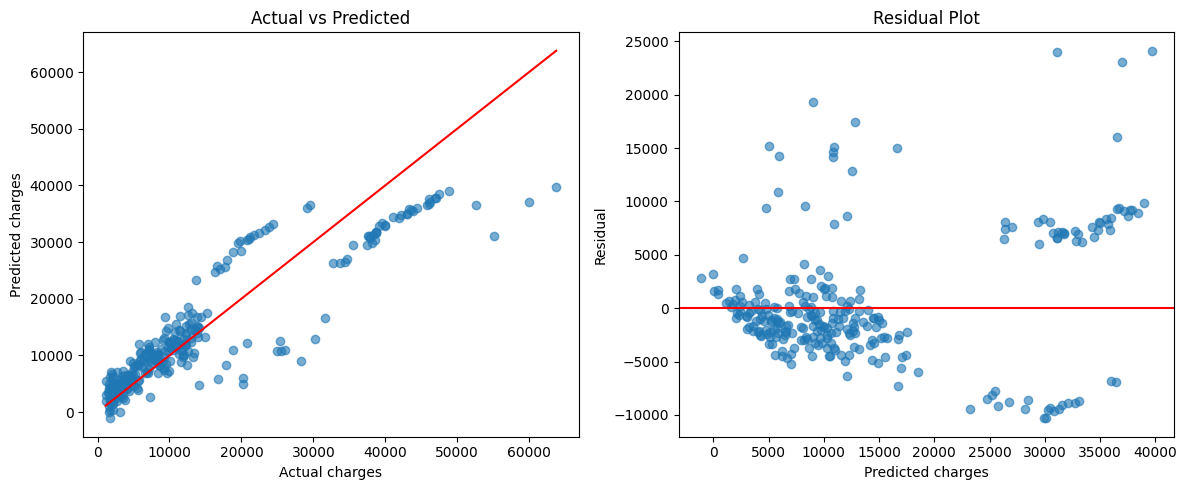

In [ ]:
insurance_residuals = insurance_test_target - insurance_test_predictions
insurance_value_limits = [insurance_test_target.min(), insurance_test_target.max()]

insurance_figure, insurance_axes = plt.subplots(1, 2, figsize=(12, 5))

insurance_axes[0].scatter(insurance_test_target, insurance_test_predictions, alpha=0.6)
insurance_axes[0].plot(insurance_value_limits, insurance_value_limits, color="red")
insurance_axes[0].set_xlabel("Actual charges")
insurance_axes[0].set_ylabel("Predicted charges")
insurance_axes[0].set_title("Actual vs Predicted")

insurance_axes[1].scatter(insurance_test_predictions, insurance_residuals, alpha=0.6)
insurance_axes[1].axhline(0, color="red")
insurance_axes[1].set_xlabel("Predicted charges")
insurance_axes[1].set_ylabel("Residual")
insurance_axes[1].set_title("Residual Plot")

plt.tight_layout()
plt.show()

Pada biaya aktual yang relatif rendah, banyak titik berkumpul cukup dekat dengan garis merah. ini menunjukkan prediksi model relatif mendekati nilai sebenarnya pada sebagian data tersebut.

Pada biaya yang lebih tinggi, terdapat sejumlah titik yang jauh dari garis merah. beberapa nilai diprediksi terlalu rendah, sedangkan sebagian lainnya terlalu tinggi. Hal tersebut menunjukkan bahwa model masih mengalami kesulitan memprediksi beberapa kasus dengan biaya tinggi. Kemungkinan hal tersebut disebabkan oleh adanya interaksi antarfitur yang belum bisa ditangkap sepenuhnya oleh model linear sederhana.

Titik-titik tidak tersebar secara acak dan merata di sekitar garis nol. Terlihat beberapa kelompok titik dengan residual negatif maupun positif yang cukup besar. Ada juga beberapa titik dengan residual hingga sekitar 24.000.

Hal tersebut menunjukkan bahwa model masih menghasilkan kesalahan prediksi yang besar pada beberapa observasi karena beberapa interaksi antarfitur yang belum tertangkap sepenuhnya.

# Iris Flower Classification

## Load Data

In [ ]:
iris_dataset_directory = Path(kagglehub.dataset_download(IRIS_DATASET_HANDLE))
iris_csv_paths = sorted(iris_dataset_directory.rglob("*.csv"))
iris_dataframe = pd.read_csv(iris_csv_paths[0])
iris_dataframe.columns = iris_dataframe.columns.str.strip().str.lower()

Using Colab cache for faster access to the 'iris-flower-dataset' dataset.


sama seperti dataset medical insurance cost, dataset didownload menggunakan kagglehub dan diubah menjadi dataframe

## Data Inspection

In [ ]:
display(iris_dataframe.head())
iris_dataframe.info()
display(iris_dataframe.describe(include="all").T)
print("Missing values per column:")
print(iris_dataframe.isna().sum())
print("Duplicated rows:", iris_dataframe.duplicated().sum())
display(iris_dataframe.iloc[:, -1].value_counts())

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
sepal_length,150.0,NaN,NaN,NaN,5.843333,0.828066,4.3,5.1,5.8,6.4,7.9
sepal_width,150.0,NaN,NaN,NaN,3.054,0.433594,2.0,2.8,3.0,3.3,4.4
petal_length,150.0,NaN,NaN,NaN,3.758667,1.76442,1.0,1.6,4.35,5.1,6.9
petal_width,150.0,NaN,NaN,NaN,1.198667,0.763161,0.1,0.3,1.3,1.8,2.5
species,150,3,Iris-setosa,50,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Missing values per column:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64
Duplicated rows: 3


,count
species,
Iris-setosa,50
Iris-versicolor,50
Iris-virginica,50


Hasil pengecekkan menunjukkan tidak ada data yang hilang (missing values) dan terdapat 3 baris data duplikat yang menunjukkan kualitas dataset baik dan siap diproses.

## Preprocessing

In [ ]:
iris_dataframe = iris_dataframe.drop(columns=[column for column in iris_dataframe.columns if column == "id"])
iris_dataframe = iris_dataframe.drop_duplicates().reset_index(drop=True)

iris_target_column = iris_dataframe.columns[-1]
iris_features = iris_dataframe.drop(columns=[iris_target_column])

iris_label_encoder = LabelEncoder()
iris_target = pd.Series(iris_label_encoder.fit_transform(iris_dataframe[iris_target_column]), name=iris_target_column)
iris_class_names = iris_label_encoder.classes_

iris_numeric_columns = iris_features.select_dtypes(include="number").columns.tolist()

(
    iris_train_raw_features,
    iris_test_raw_features,
    iris_train_target,
    iris_test_target,
) = train_test_split(
    iris_features,
    iris_target,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=iris_target,
)

iris_numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
iris_preprocessor = ColumnTransformer(
    [("numeric", iris_numeric_pipeline, iris_numeric_columns)],
    verbose_feature_names_out=False,
)
iris_preprocessor.set_output(transform="pandas")

iris_train_features = iris_preprocessor.fit_transform(iris_train_raw_features)
iris_test_features = iris_preprocessor.transform(iris_test_raw_features)

iris_cross_validator = StratifiedKFold(n_splits=CROSS_VALIDATION_FOLDS, shuffle=True, random_state=RANDOM_STATE)
iris_model_results = {}

display(iris_train_features.head())
print("Classes:", list(iris_class_names))
print("Train shape:", iris_train_features.shape)
print("Test shape:", iris_test_features.shape)

,sepal_length,sepal_width,petal_length,petal_width
65,-0.040953,-0.743554,0.179257,-0.279931
88,-0.391551,-0.967770,0.349770,-0.015803
101,0.543377,-0.295122,1.031820,0.776584
50,1.244572,0.153310,0.633957,0.380391
127,1.595170,-0.070906,1.145495,0.512455


Classes: ['Iris-setosa', 'Iris-versicolor', 'Iris-virginica']
Train shape: (117, 4)
Test shape: (30, 4)


Kolom id dihapus dan row duplikat dihapus.

Kolom targetnya adalah species yang diubah menjadi representasi numerik menggunakan LabelEncoder, dan kolom inputnya adalah sisanya.

Kolom inputnya distandarisasi menggunakan StandardScaler(), dan semua jenisnya adalah numerik sehingga Imputernya hanya menggunakan strategi median, tidak ada yang kategorikal seperti dataset sebelumnya.

## Model: SVM

In [ ]:
from sklearn.svm import SVC


class SVMModel:
    def __init__(self, kernel="rbf", regularization=1.0, random_state=42):
        self.estimator = SVC(kernel=kernel, C=regularization, gamma="scale", random_state=random_state)

    def train(self, features, target):
        self.estimator.fit(features, target)
        return self

    def predict(self, features):
        return self.estimator.predict(features)

    def cross_validate(self, features, target, cross_validator):
        return cross_val_score(self.estimator, features, target, cv=cross_validator, scoring="accuracy")

Sama seperti sebelumnya, kami menggunakan model SVM dari scikit-learn, tidak membuat dari awal atau from scratch.

SVM adalah algoritma yang umumnya digunakan untuk mengklasifikasikan data ke dalam beberapa kelas. SVM mencari batas pemisah (hyperplane) terbaik agar kelompok data dapat dibedakan.

In [ ]:
svm_model = SVMModel(kernel="rbf", regularization=1.0, random_state=RANDOM_STATE)
svm_model.train(iris_train_features, iris_train_target)

svm_predictions = svm_model.predict(iris_test_features)
svm_cv_scores = svm_model.cross_validate(iris_train_features, iris_train_target, iris_cross_validator)

Kernel yang kami gunakan adalah Radial basis function, karena ini adalah masalah klasifikasi dan datanya tidak bisa dipisahkan secara linear.

Regularizationnya adalah 1.0 untuk memaksimalkan jarak margin antara batas keputusan (hyperplane) dengan data terdekat (support vectors) dan meminimalkan kesalahan klasifikasi. Nilai 1.0 adalah nilai default untuk menjaga keseimbangan margin tanpa overfitting ekstrem.

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      0.90      0.95        10
 Iris-virginica       0.91      1.00      0.95        10

       accuracy                           0.97        30
      macro avg       0.97      0.97      0.97        30
   weighted avg       0.97      0.97      0.97        30

Cross validation accuracy: 0.9746 +/- 0.0335


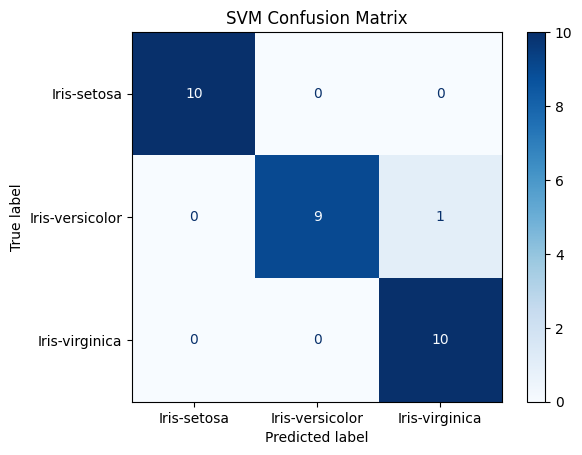

In [ ]:
svm_metrics = {
    "accuracy": accuracy_score(iris_test_target, svm_predictions),
    "precision_macro": precision_score(iris_test_target, svm_predictions, average="macro", zero_division=0),
    "recall_macro": recall_score(iris_test_target, svm_predictions, average="macro", zero_division=0),
    "f1_macro": f1_score(iris_test_target, svm_predictions, average="macro", zero_division=0),
    "cv_accuracy_mean": svm_cv_scores.mean(),
    "cv_accuracy_std": svm_cv_scores.std(),
}
iris_model_results["SVM"] = svm_metrics

print(classification_report(iris_test_target, svm_predictions, target_names=iris_class_names, zero_division=0))
print("Cross validation accuracy:", round(svm_cv_scores.mean(), 4), "+/-", round(svm_cv_scores.std(), 4))
ConfusionMatrixDisplay.from_predictions(
    iris_test_target,
    svm_predictions,
    display_labels=iris_class_names,
    cmap="Blues",
)
plt.title("SVM Confusion Matrix")
plt.show()

Hasil berdasarkan confusion matrix adalah
10 dari 10 bunga diprediksi dengan benar sebagai Setosa.
9 bunga diprediksi dengan benar sebagai Versicolor, tetapi 1 bunga salah diprediksi sebagai Virginica (FN).
seluruh 10 bunga diprediksi dengan benar sebagai Virginica, tetapi terdaapat 1 bunga diprediksi sebagai Virginica padahal kelas lain (Versicolor) (FP).

Performa klasifikasi yang dihasilkan sangat baik dengan weighted average nya 0.97 atau 97%, serta rata-rata akurasi cross validation sebesar 97.46% $\pm$ 3.35% artinya model masih akurat dalam mengklasifikasikan data.

Model masih kesulitan dalam membedakan Iris versicolor dan Iris virginica. Hal ini disebabkan oleh morfologi ukuran sepalnya yang berdekatan nilainya.